# Trabajo de fin de master

Este es el orden de trabajo

1. Carga de datos.
2. Análisis exploratorio inicial.
3. Preprocesamiento de datos.
4. Separación en entrenamiento y test.
5. Creación de 4 modelos.
6. Validación cruzada.
7. Entrenamiento y Evaluacion.
8. Comparacion de modelos con la curva ROC.
9. Conclusiones finales.


*Los nombres de la columnas del dadasets tienen un espacio al inicio

# 1- Carga de datos e importaciones de librerias

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
import shap

#Cargamos el dataset para crear el dataframe
df_creditos = pd.read_csv("loan_approval_dataset.csv")

# 2- Analisis exploratorio inicial

In [23]:
df_creditos.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


### Tamaño del dataframe

In [24]:
df_creditos.shape

(4269, 13)

In [25]:
df_creditos.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 433.7 KB


In [26]:
df_creditos.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


### Valores nulos

In [27]:
df_creditos.isnull().sum()

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64

### Balance del Target

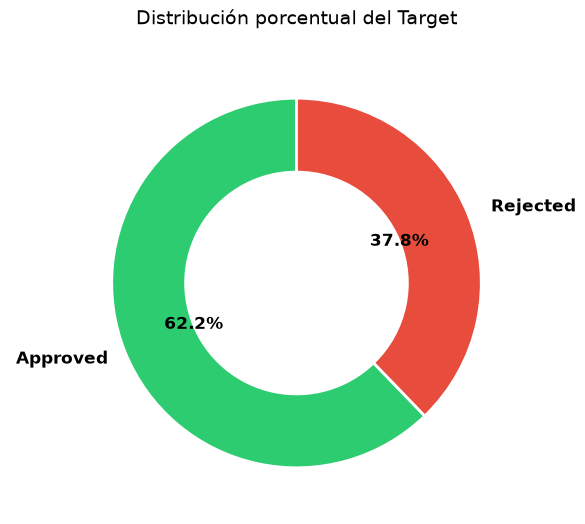

In [28]:
#Obtengo el conteo de cada clase
conteo =  df_creditos[" loan_status"].value_counts()

plt.figure(figsize=(6, 6))

#Creamos el grafico dona
plt.pie(
    conteo, 
    labels=conteo.index, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=['#2ecc71', '#e74c3c'],  # Verde para aprobado, rojo para rechazado
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2), 
    textprops={'fontsize': 12, 'weight': 'bold'}
)

plt.title('Distribución porcentual del Target', fontsize=14, pad=20)
plt.show()






### Relacion del target con las variables predictoras

#### Nombres columnas

- loan_id ===> id_prestamo
- no_of_dependents ===> numero de dependientes
- education ===> educacion 
- self_employed ===> autonomo
- income_annum ===> ingresos anuales
- loan_amount ===> importe de l prestamo
- loan_term ===> plazo del prestamo
- cibil_score ===> puntuacion cibil
- residential_assets_value ===> valor de activos residenciales
- commercial_assets_value ===> valor de los activos comerciales
- luxury_assets_value ===> valor de los activos de lujo
- bank_asset_value ===> valor de los activos bancarios
- loan_status ===> estado del prestamo


In [29]:
#Hacemos una copia del DataFrame para conservar el original
df_encoded = df_creditos.copy()

#Convertimos las tres columnas de texto a numericas usando Pandas
df_encoded[" education"] = df_creditos[" education"].astype("category").cat.codes
df_encoded[" self_employed"] = df_creditos[" self_employed"].astype("category").cat.codes
df_encoded[" loan_status"] = df_creditos[" loan_status"].astype("category").cat.codes

#X son variables predictoras e y es el target codificado (0 y 1)
X = df_encoded.drop(columns=[" loan_status"])
y = df_encoded[" loan_status"]

#Calculamos la Información Mutua
mi_scores = mutual_info_classif(X, y, random_state=42)

#Crearmos un DataFrame resumen ordenado
df_resumen = pd.DataFrame({
    "Variable": X.columns,
    "Mutual_Information_Score": mi_scores
}).sort_values(by="Mutual_Information_Score", ascending=False).reset_index(drop=True)

df_resumen


,Variable,Mutual_Information_Score
0,cibil_score,0.507958
1,loan_term,0.022652
2,commercial_assets_value,0.012054
3,luxury_assets_value,0.005376
4,loan_amount,0.000912
5,self_employed,0.000733
6,loan_id,0.000322
7,no_of_dependents,0.000000
8,education,0.000000
9,income_annum,0.000000


Como podemos ver en estos resultados existen variables que no influyen en la concesion del credito asi que descartamos las cinco ultimas mas el loan_id que tambien es practicamente irrelevante

# 3- Preprocesamiento de datos

#### Seleccion de variables

Estas son las variables que nos vamos a quedar 

- cibil_score ===> puntuacion cibil
- loan_term ===> plazo del prestamo
- commercial_assets_value ===> valor de los activos comerciales
- luxury_assets_value ===> valor de los activos de lujo
- loan_amount ===> importe del prestamo
- self_employed ===> autonomo

In [30]:
#Hacemos una copia del Dataframe original
df_model = df_creditos.copy()

#Convertimos las columnas de texto a numéricas antes de filtrar
df_model[" self_employed"] = df_model[" self_employed"].astype("category").cat.codes
df_model[" loan_status"] = df_model[" loan_status"].astype("category").cat.codes

#Definimos la lista de columnas que formaran el nuevo Dataframe
columnas_seleccionadas = [
    " cibil_score", 
    " loan_term", 
    " commercial_assets_value", 
    " luxury_assets_value", 
    " loan_amount", 
    " self_employed",
    " loan_status"
    ]

#Creamos el nuevo Dataframe definitivo para el modelo
df_final = df_model[columnas_seleccionadas].copy()

df_final.head()

,cibil_score,loan_term,commercial_assets_value,luxury_assets_value,loan_amount,self_employed,loan_status
0,778,12,17600000,22700000,29900000,0,0
1,417,8,2200000,8800000,12200000,1,1
2,506,20,4500000,33300000,29700000,0,1
3,467,8,3300000,23300000,30700000,0,1
4,382,20,8200000,29400000,24200000,1,1


# 4- Separacion de datos, entrenamiento y test

In [31]:
#Seleccion de columnas predictoras y target
X = df_final.drop(columns=[" loan_status"])
y = df_final[" loan_status"]


#Hacemos la separacion con un 80% de entrenamiento y 20% de test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((3415, 6), (854, 6), (3415,), (854,))

#### Antes de continuar vamos a hacer un escalado para poner las variables en el mismo rango de tamaño ya que es una dataset con ciertas diferencias en este sentido

In [32]:
scaler = StandardScaler()

#Variables predictoras
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), 
    columns=X_train.columns, 
    index=X_train.index
)

#Variables predictoras del test
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), 
    columns=X_test.columns, 
    index=X_test.index
)

X_train_scaled.head()

,cibil_score,loan_term,commercial_assets_value,luxury_assets_value,loan_amount,self_employed
1224,-0.806352,0.549181,1.942808,0.659076,0.983585,0.998537
478,1.110842,-0.500709,0.216625,-0.582560,-0.717129,0.998537
3065,-0.557291,0.549181,-0.796070,-1.066029,-1.228455,-1.001465
326,-0.476201,0.199218,-1.141306,-0.516632,-0.417003,0.998537
2991,-0.238724,0.199218,-0.819085,-0.978125,-0.728245,-1.001465


# 5- Creacion de modelos
#### Vamos a hacer la comparativa con cuatro modelos los tres que vimos en el proyecto de clase y uno mas que es KNN

In [33]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN" : KNeighborsClassifier(n_neighbors=5, weights="distance", metric="euclidean", n_jobs=1)
}

models

{'Logistic Regression': LogisticRegression(max_iter=1000),
 'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
 'Random Forest': RandomForestClassifier(random_state=42),
 'KNN': KNeighborsClassifier(metric='euclidean', n_jobs=1, weights='distance')}

# 6- Validacion cruzada
#### Hacemos una validación cruzada para examinar el modelo varias veces con distintos trozos de datos y confirmar que su nota no es fruto de la casualidad.

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train_scaled,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1", "roc_auc"]
    )

    cv_results.append({
        "model": model_name,
        "accuracy_cv_mean": scores["test_accuracy"].mean(),
        "f1_cv_mean": scores["test_f1"].mean(),
        "roc_auc_cv_mean": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(by="f1_cv_mean", ascending=False)
cv_results_df

,model,accuracy_cv_mean,f1_cv_mean,roc_auc_cv_mean
2,Random Forest,0.971596,0.962264,0.994438
1,Decision Tree,0.961933,0.948759,0.992861
3,KNN,0.930600,0.908364,0.980262
0,Logistic Regression,0.910981,0.881706,0.964600


# 7- Entrenamiento y Evaluacion

Voy a ir haciendo los modelos uno por uno para ver mejor los resultados del classification report y la matriz de confusion

In [35]:
#Empezaremos con logistic regresion
model_logistic = models["Logistic Regression"]

model_logistic.fit(X_train_scaled, y_train) 

loc_predic = model_logistic.predict(X_test_scaled)


cr_logistic = classification_report(y_test, loc_predic, digits=4)

cm_logistic = confusion_matrix(y_test, loc_predic)

print(f"{"=" * 65}\nLogistic Regresion\n{"=" * 65}")
print(f"Classification report\n{cr_logistic}")
print(f"Matriz de confusion\n{cm_logistic}")



Logistic Regresion
Classification report
              precision    recall  f1-score   support

           0     0.9207    0.9623    0.9411       531
           1     0.9331    0.8638    0.8971       323

    accuracy                         0.9251       854
   macro avg     0.9269    0.9131    0.9191       854
weighted avg     0.9254    0.9251    0.9244       854

Matriz de confusion
[[511  20]
 [ 44 279]]


In [36]:
#Seguimos con Decision Tree
model_decision = models["Decision Tree"]

model_decision.fit(X_train_scaled, y_train) 

dec_predic = model_decision.predict(X_test_scaled)


cr_decision = classification_report(y_test, dec_predic, digits=4)

cm_decision = confusion_matrix(y_test, dec_predic)

print(f"{"=" * 65}\nDecision Tree\n{"=" * 65}")
print(f"Classification report\n{cr_decision}")
print(f"Matriz de confusion\n{cm_decision}")



Decision Tree
Classification report
              precision    recall  f1-score   support

           0     0.9511    0.9887    0.9695       531
           1     0.9801    0.9164    0.9472       323

    accuracy                         0.9614       854
   macro avg     0.9656    0.9526    0.9584       854
weighted avg     0.9621    0.9614    0.9611       854

Matriz de confusion
[[525   6]
 [ 27 296]]


In [37]:
#Continuamos con Random Forest
model_random = models["Random Forest"]

model_random.fit(X_train_scaled, y_train) 

ran_predic = model_random.predict(X_test_scaled)


cr_random = classification_report(y_test, ran_predic, digits=4)

cm_random = confusion_matrix(y_test, ran_predic)

print(f"{"=" * 65}\nRandom Forest\n{"=" * 65}")
print(f"Classification report\n{cr_random}")
print(f"Matriz de confusion\n{cm_random}")



Random Forest
Classification report
              precision    recall  f1-score   support

           0     0.9704    0.9868    0.9785       531
           1     0.9777    0.9505    0.9639       323

    accuracy                         0.9731       854
   macro avg     0.9740    0.9686    0.9712       854
weighted avg     0.9731    0.9731    0.9730       854

Matriz de confusion
[[524   7]
 [ 16 307]]


In [38]:
#Y por ultimo KNN
model_knn = models["KNN"]

model_knn.fit(X_train_scaled, y_train) 

knn_predic = model_knn.predict(X_test_scaled)


cr_knn = classification_report(y_test, knn_predic, digits=4)

cm_knn = confusion_matrix(y_test, knn_predic)

print(f"{"=" * 65}\nKNN\n{"=" * 65}")
print(f"Classification report\n{cr_knn}")
print(f"Matriz de confusion\n{cm_knn}")


KNN
Classification report
              precision    recall  f1-score   support

           0     0.9320    0.9548    0.9433       531
           1     0.9226    0.8854    0.9036       323

    accuracy                         0.9286       854
   macro avg     0.9273    0.9201    0.9234       854
weighted avg     0.9284    0.9286    0.9283       854

Matriz de confusion
[[507  24]
 [ 37 286]]


# 8- Comparacion de modelos con la curva ROC

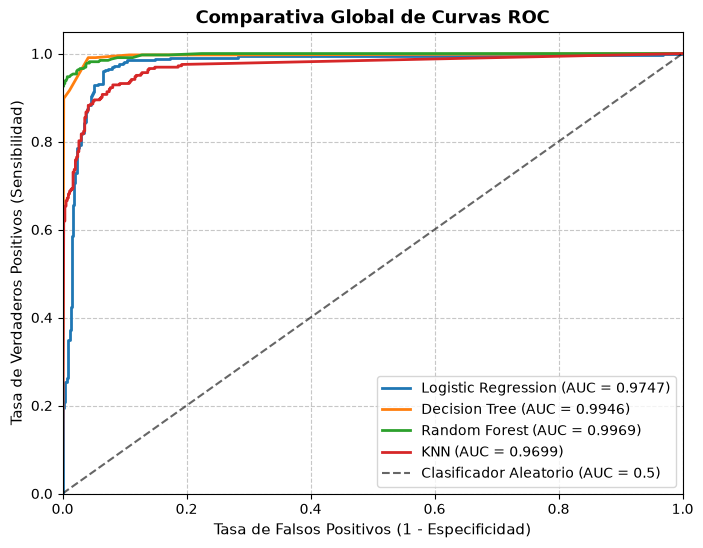

In [39]:
plt.figure(figsize=(8, 6))

for model_name, model in models.items():
    #Obtenemos las probabilidades de la clase positiva
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    #Calculamos FPR, TPR y el AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)
    
    #Pintamos la línea de cada modelo
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.4f})', linewidth=2)

    #Línea diagonal de referencia (clasificador aleatorio)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.5)', alpha=0.6)

#Configuración estética de la gráfica para el TFM
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=11)
plt.title('Comparativa Global de Curvas ROC', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 9- Conclusiones finales

Primero creamos un nuevo data frame para comparar los modelos y ordenalos. 
Volvemos a utilizar el classification report para crear un diccionario y poder hacer la comparativa.

In [40]:
cr_logistic = classification_report(y_test, loc_predic, digits=4, output_dict=True)
cr_decision = classification_report(y_test, dec_predic, digits=4, output_dict=True)
cr_random = classification_report(y_test, ran_predic, digits=4, output_dict=True)
cr_knn = classification_report(y_test, knn_predic, digits=4, output_dict=True)

#Agrupamos 
reportes_con_nombre = [
    ("Logistic Regresion", cr_logistic),
    ("Decision Tree", cr_decision),
    ("Random Forest", cr_random),
    ("KNN", cr_knn)
]

metrics_data = []

#Recorremos la lista extrayendo las metricas comparativas
for model_name, report in reportes_con_nombre:
    metrics_data.append({
        "Modelo": model_name,
        "Accuracy": report["accuracy"],
        "Precision": report["1"]["precision"], #Clase positiva (1)
        "F1-score": report["1"]["f1-score"]      #Clase positiva (1)
    })

#Creamos el DataFrame y lo ordenamos de mayor a menor por el F1-score
df_comparativo = pd.DataFrame(metrics_data).sort_values(by="F1-score", ascending=False)

print("--- Tabla comparativa de modelos ---")
display(df_comparativo) 


--- Tabla comparativa de modelos ---


,Modelo,Accuracy,Precision,F1-score
2,Random Forest,0.973068,0.977707,0.963893
1,Decision Tree,0.961358,0.980132,0.947200
3,KNN,0.928571,0.922581,0.903633
0,Logistic Regresion,0.925059,0.933110,0.897106


Conclusión: Los datos confirman de forma clara que Random Forest es la mejor opción para este proyecto.

### Aplicamos SHAP

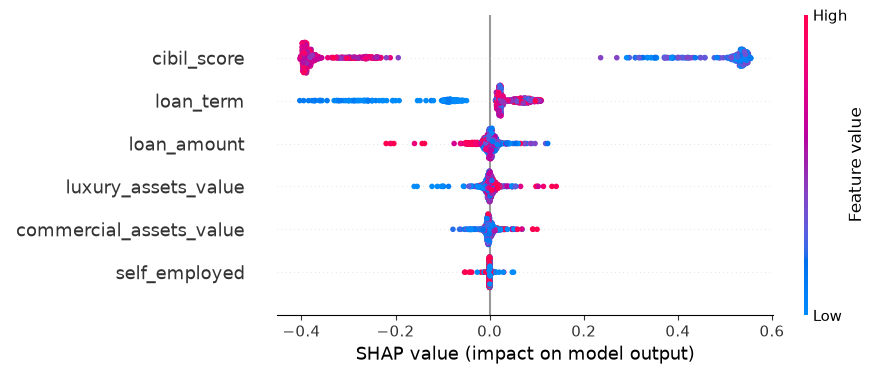

In [41]:
explainer = shap.Explainer(model_random)

#Calculamos los valores SHAP
shap_values = explainer(X_test_scaled)

#Nos quedamos únicamente con la clase positiva (índice 1) para bajarlo a 2 dimensiones
shap_values_clase = shap_values[:, :, 1]

#Generamos el gráfico de enjambre
shap.plots.beeswarm(shap_values_clase)

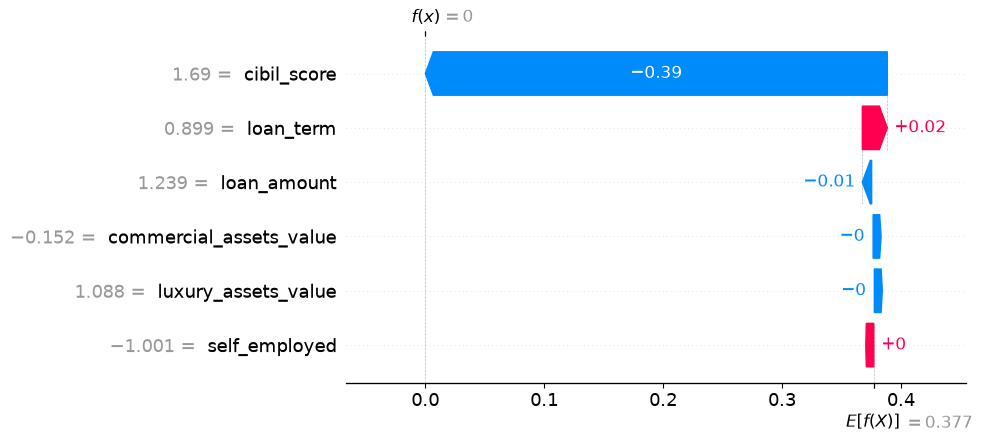

In [42]:
#Muestra la explicación detallada para el primer cliente
shap.plots.waterfall(shap_values_clase[0])

Conclusión:
El análisis SHAP demuestra que el modelo toma decisiones de manera totalmente lógica y coherente con el sentido común bancario, basando sus veredictos principalmente en la solvencia y el historial del solicitante.